### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** explore the raw sensor data (EDA), then try the "predict sensor values for specific times of the day" task from the assignment brief with simple regressions.

**Data:** the three raw exports in `../data/raw/` (3–17 June 2025, about 1.85 M readings). The saved outputs below come from the original run on the same raw CSVs.

**Split:** random 80/20 `train_test_split` (shuffled) for the models. **Horizon:** none (these models map time of day to a value; they do not forecast from past readings).

**Key result (saved output) vs baseline:**

| Target | Model | RMSE | Baseline: predict the mean (RMSE = standard deviation) |
|---|---|---|---|
| Temperature | Polynomial regression (degree 2) | 0.345 (MAE 0.25) | 0.345 |
| Humidity | Ridge (multi-output) | 2.747 | 2.752 |
| VOC | Ridge / Linear / Poly / Lasso | 0.22 | 0.222 |

The baseline numbers were computed later, during a review of the project.

**Caveats**
- The models use only hour, minute and second as features, with a shuffled split. Their RMSE equals the standard deviation of the target, so R² ≈ 0: they have **no skill**.
- The report called the polynomial model a forecast "based on past readings". It is not; it only uses the time of day.
- The EDA part (cells up to the "sensors overview" plot) is the useful part of this notebook.


##### CONTENTS: voc, temperature & humidity ML Predictions

In [1]:
# !pip install xgboost
#!pip install pandas numpy matplotlib scikit-learn.

In [9]:
# --- Importing Required Libraries ---

import pandas as pd         # Data manipulation and analysis
import numpy as np          # Numerical operations
import matplotlib.pyplot as plt  # Plotting library
import matplotlib.dates as mdates  # Handling date formatting in plots

# Machine learning models and preprocessing
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import Ridge
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.svm import SVR
    
# Model selection and evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error


In [3]:
# Loading and reading the dataset.
df_humidity = pd.read_csv("../data/raw/humidity_raw.csv.gz")
df_temperature = pd.read_csv("../data/raw/temperature_raw.csv.gz")
df_voc = pd.read_csv("../data/raw/voc_raw.csv.gz")

In [4]:
# --- Exploratory Data Overview and Preprocessing ---

# List of dataframes with names for iteration
dfs = {
    "Humidity": df_humidity,
    "Temperature": df_temperature,
    "VOC": df_voc
}

for name, df in dfs.items():
    print(f"--- {name} Data ---\n")
    
    # Print first 5 rows
    print("Sample data:")
    print(df.head(), "\n")
    
    # Print shape
    print(f"Shape: {df.shape}\n")
    
    # Print info
    print("Info:")
    print(df.info(), "\n")
    
    # Check for duplicates
    dup_count = df.duplicated().sum()
    print(f"Number of duplicate rows: {dup_count}\n")
    
    # Check for missing values
    print("Missing values per column:")
    print(df.isnull().sum(), "\n")
    
    # Describe stats
    print("Statistical summary:")
    print(df.describe(), "\n")
    
    # Convert 'time' column to datetime if exists
    if 'time' in df.columns:
        df['time'] = pd.to_datetime(df['time'], errors='coerce')
        print("'time' column converted to datetime.\n")
    
    print("="*50, "\n")


--- Humidity Data ---

Sample data:
                             time      value
0  2025-06-03T00:00:00.150610304Z  38.861900
1   2025-06-03T00:00:03.59793668Z  38.829792
2  2025-06-03T00:00:07.042788004Z  38.807629
3  2025-06-03T00:00:10.281933071Z  38.831055
4  2025-06-03T00:00:13.623674462Z  38.818520 

Shape: (373745, 2)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373745 entries, 0 to 373744
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   time    373745 non-null  object 
 1   value   373745 non-null  float64
dtypes: float64(1), object(1)
memory usage: 5.7+ MB
None 

Number of duplicate rows: 0

Missing values per column:
time     0
value    0
dtype: int64 

Statistical summary:
               value
count  373745.000000
mean       40.139220
std         2.752175
min        34.538097
25%        38.086861
50%        39.995064
75%        42.023014
max        52.125210 

'time' column converted to datetime.


-

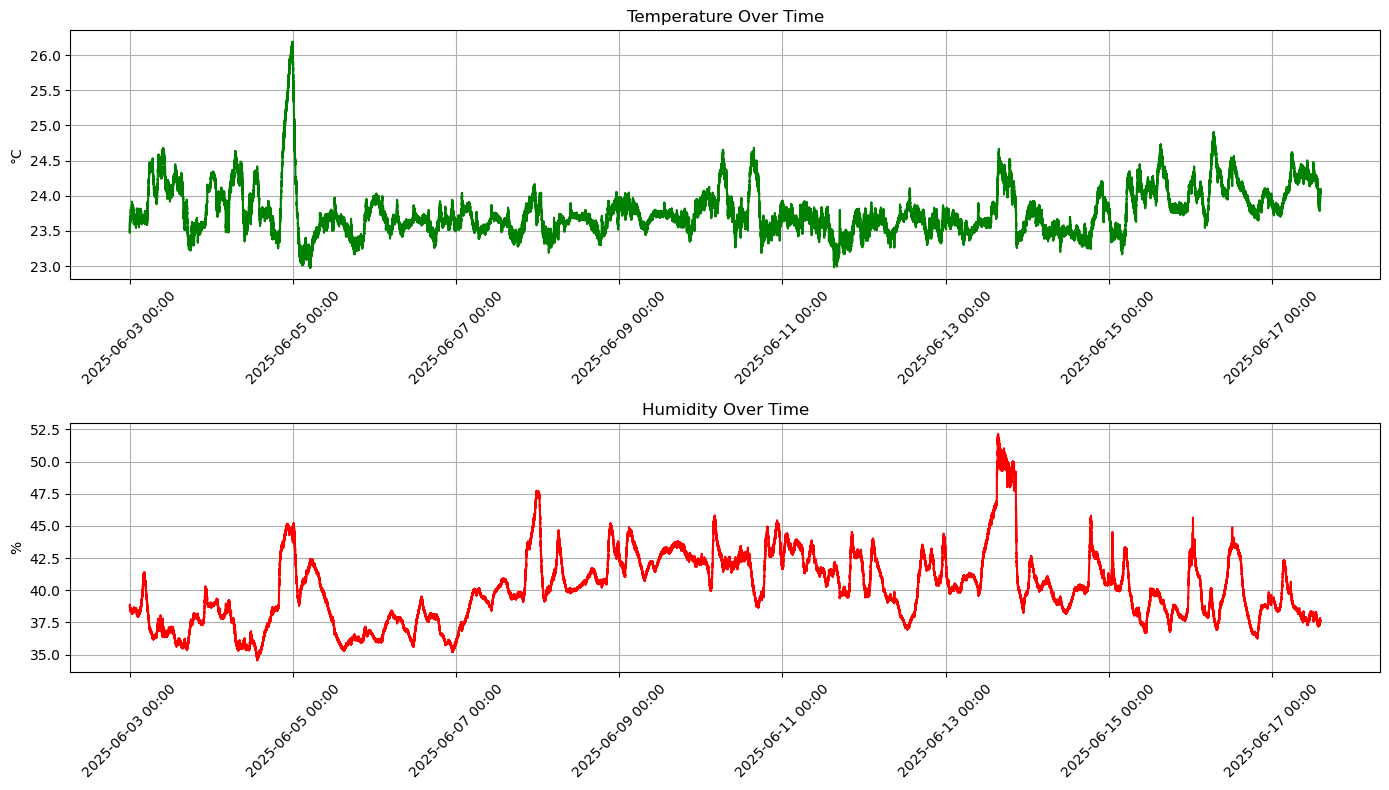

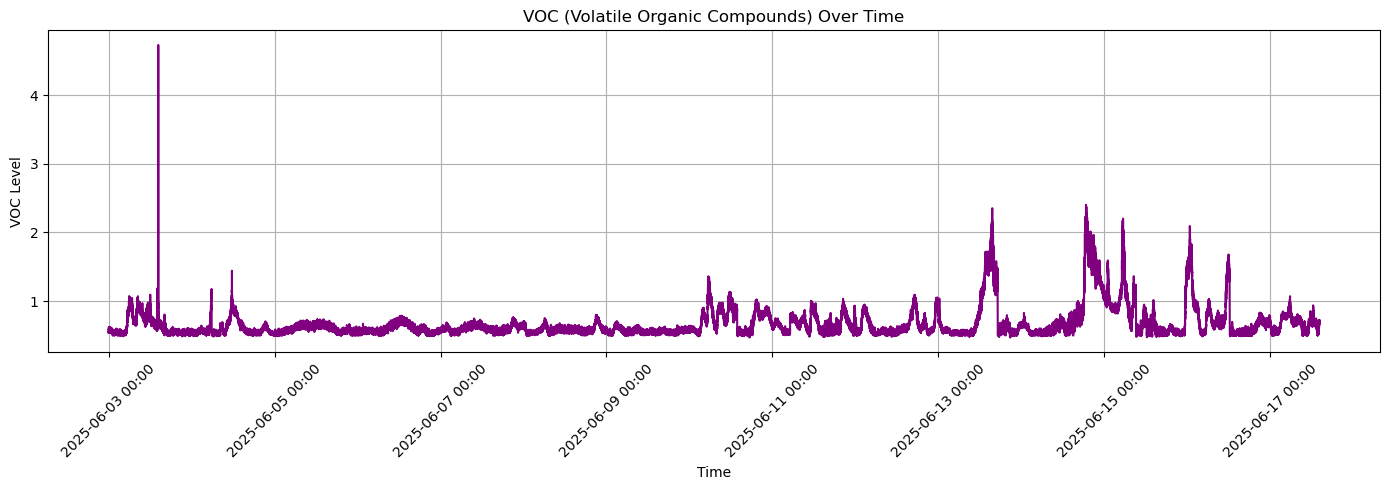

In [30]:
# --- Plot Temperature, VOC and Humidity over entire period ---

plt.figure(figsize=(14, 8))

# Temperature plot
plt.subplot(2, 1, 1)
plt.plot(df_temperature["time"], df_temperature["value"], label="Temperature (°C)", color="green")
plt.title("Temperature Over Time")
plt.ylabel("°C")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

# Humidity plot
plt.subplot(2, 1, 2)
plt.plot(df_humidity["time"], df_humidity["value"], label="Humidity (%)", color="red")
plt.title("Humidity Over Time")
plt.ylabel("%")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("temperature_humidity_over_time.png")
plt.show()

# --- VOC Plot---

plt.figure(figsize=(14, 5))
plt.plot(df_voc["time"], df_voc["value"], label="VOC", color="purple")
plt.title("VOC (Volatile Organic Compounds) Over Time")
plt.ylabel("VOC Level")
plt.xlabel("Time")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("voc_over_time.png")
plt.show()


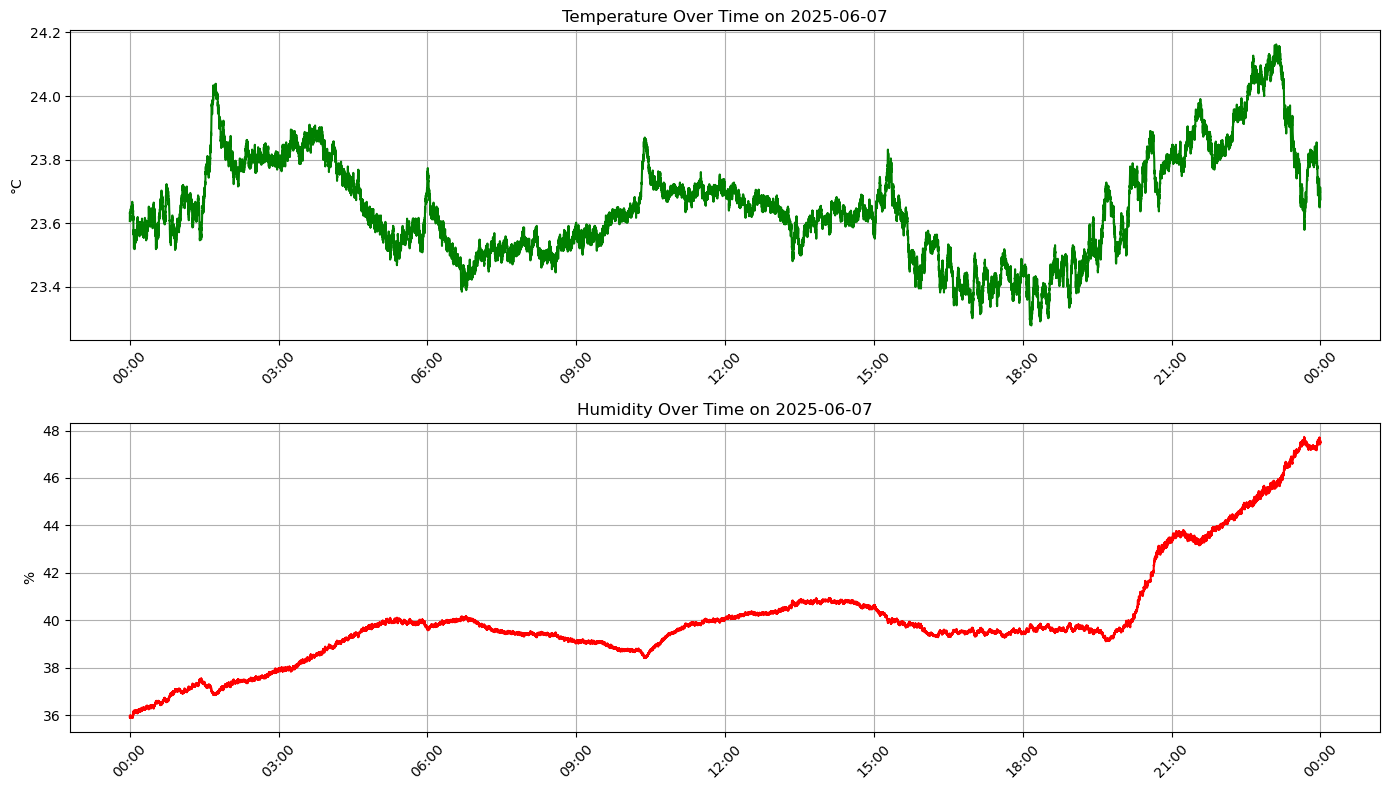

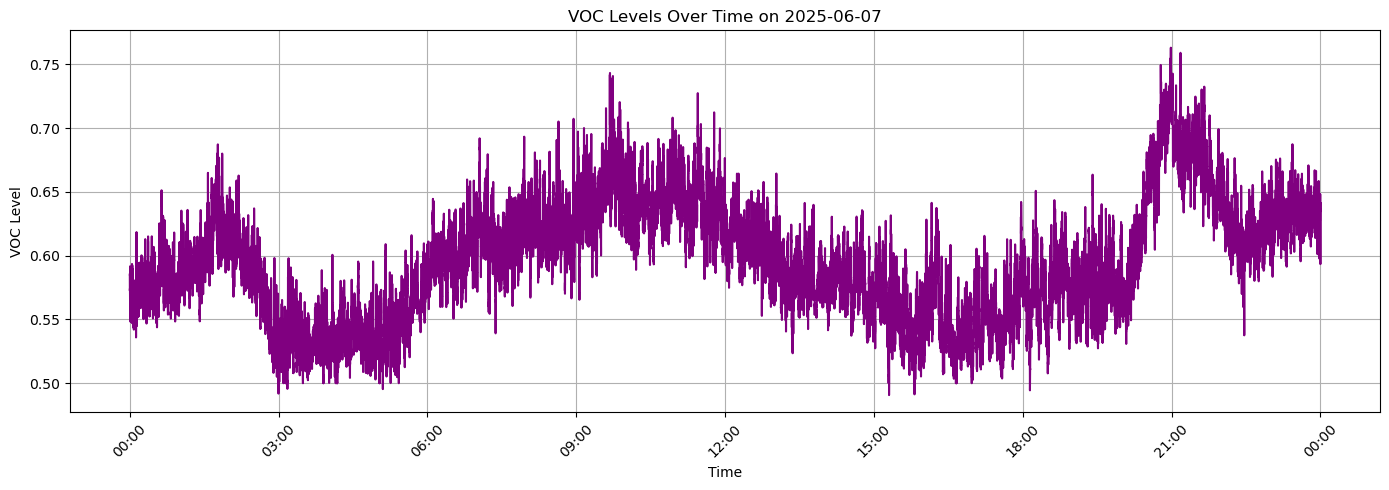

In [25]:
# PLots
# --- Plot Temperature and Humidity for a Specific Date ---

selected_date = pd.to_datetime("2025-06-07").date()

# Filter datasets for the selected date
temp_day = df_temperature[df_temperature["time"].dt.date == selected_date]
humidity_day = df_humidity[df_humidity["time"].dt.date == selected_date]

plt.figure(figsize=(14, 8))

plt.subplot(2, 1, 1)
plt.plot(temp_day["time"], temp_day["value"], label="Temperature (°C)", color="green")
plt.title(f"Temperature Over Time on {selected_date}")
plt.ylabel("°C")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

plt.subplot(2, 1, 2)
plt.plot(humidity_day["time"], humidity_day["value"], label="Humidity (%)", color="red")
plt.title(f"Humidity Over Time on {selected_date}")
plt.ylabel("%")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(f"temperature_humidity_{selected_date}.png")
plt.show()

# --- Plot VOC for a Specific Date ---

selected_date = pd.to_datetime("2025-06-07").date()
voc_day = df_voc[df_voc["time"].dt.date == selected_date]

plt.figure(figsize=(14, 5))
plt.plot(voc_day["time"], voc_day["value"], label="VOC", color="purple")
plt.title(f"VOC Levels Over Time on {selected_date}")
plt.ylabel("VOC Level")
plt.xlabel("Time")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(f"voc_{selected_date}.png")
plt.show()

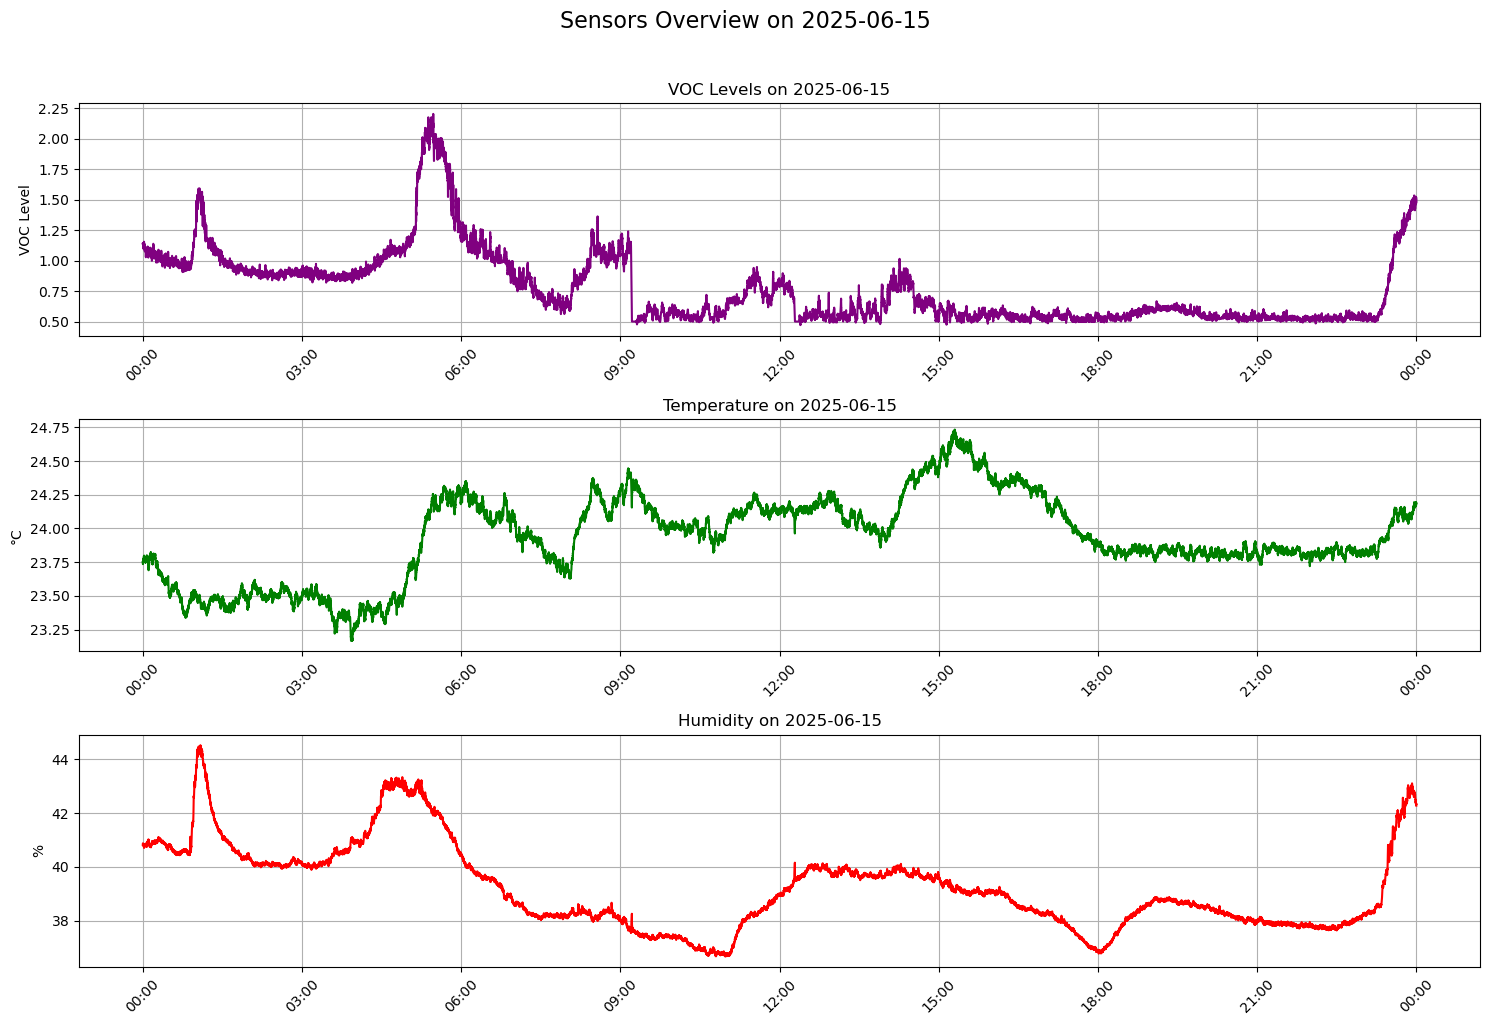

In [29]:
# --- Select specific date ---
selected_date = pd.to_datetime("2025-06-15").date()

# Filter all three datasets for the selected date
voc_day = df_voc[df_voc["time"].dt.date == selected_date]
temp_day = df_temperature[df_temperature["time"].dt.date == selected_date]
humidity_day = df_humidity[df_humidity["time"].dt.date == selected_date]

# --- Plotting VOC, Temperature, Humidity over selected day ---
plt.figure(figsize=(15, 10))

# VOC
plt.subplot(3, 1, 1)
plt.plot(voc_day["time"], voc_day["value"], label="VOC", color="purple")
plt.title(f"VOC Levels on {selected_date}")
plt.ylabel("VOC Level")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

# Temperature
plt.subplot(3, 1, 2)
plt.plot(temp_day["time"], temp_day["value"], label="Temperature (°C)", color="green")
plt.title(f"Temperature on {selected_date}")
plt.ylabel("°C")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

# Humidity
plt.subplot(3, 1, 3)
plt.plot(humidity_day["time"], humidity_day["value"], label="Humidity (%)", color="red")
plt.title(f"Humidity on {selected_date}")
plt.ylabel("%")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.grid(True)
plt.xticks(rotation=45)

plt.suptitle(f"Sensors Overview on {selected_date}", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(f"sensors_overview_{selected_date}.png")
plt.show()


---
## Time-of-day models (kept for completeness)

Kept for completeness: these models use only hour/minute/second with a random split and have no skill (R² ≈ 0). The brief asked for time-of-day prediction.


In [5]:

# ===================== HUMIDITY DATA =====================
# Sort by time and extract hour, minute, second as features
humidity_df = df_humidity.sort_values("time").copy()
humidity_df["hour"] = humidity_df["time"].dt.hour
humidity_df["minute"] = humidity_df["time"].dt.minute
humidity_df["second"] = humidity_df["time"].dt.second

# Define features and target
X_h = humidity_df[["hour", "minute", "second"]]
y_h = humidity_df["value"]

# Train-test split
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_h, y_h, test_size=0.2, random_state=42)


# ===================== TEMPERATURE DATA =====================
temperature_df = df_temperature.sort_values("time").copy()
temperature_df["hour"] = temperature_df["time"].dt.hour
temperature_df["minute"] = temperature_df["time"].dt.minute
temperature_df["second"] = temperature_df["time"].dt.second

X_t = temperature_df[["hour", "minute", "second"]]
y_t = temperature_df["value"]

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_t, y_t, test_size=0.2, random_state=42)


# ===================== VOC DATA =====================
voc_df = df_voc.sort_values("time").copy()
voc_df["hour"] = voc_df["time"].dt.hour
voc_df["minute"] = voc_df["time"].dt.minute
voc_df["second"] = voc_df["time"].dt.second

X_v = voc_df[["hour", "minute", "second"]]
y_v = voc_df["value"]

X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_v, y_v, test_size=0.2, random_state=42)


In [6]:
# Step 1: Merge all three sensors on 'time'
merged = df_humidity[['time', 'value']].rename(columns={'value': 'humidity'}).merge(
    df_temperature[['time', 'value']].rename(columns={'value': 'temperature'}),
    on='time', how='inner'
).merge(
    df_voc[['time', 'value']].rename(columns={'value': 'VOC'}),
    on='time', how='inner'
)

# Step 2: Extract time features
merged['hour'] = merged['time'].dt.hour
merged['minute'] = merged['time'].dt.minute
merged['second'] = merged['time'].dt.second

# Step 3: Define features and targets
X_all = merged[['hour', 'minute', 'second']]
y_all = merged[['humidity', 'temperature', 'VOC']]

# Step 4: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

# Step 5: Train MultiOutput model using Ridge
base_model = Ridge()
multi_model = MultiOutputRegressor(base_model)

multi_model.fit(X_train, y_train)
preds = multi_model.predict(X_test)
print("Rigde Model:")
# Step 6: Evaluate each target
for i, col in enumerate(y_all.columns):
    rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], preds[:, i]))
    mae = mean_absolute_error(y_test.iloc[:, i], preds[:, i])
    print(f"{col:<12} | RMSE: {rmse:.3f} | MAE: {mae:.3f}")

Rigde Model:
humidity     | RMSE: 2.747 | MAE: 2.185
temperature  | RMSE: 0.345 | MAE: 0.251
VOC          | RMSE: 0.222 | MAE: 0.138


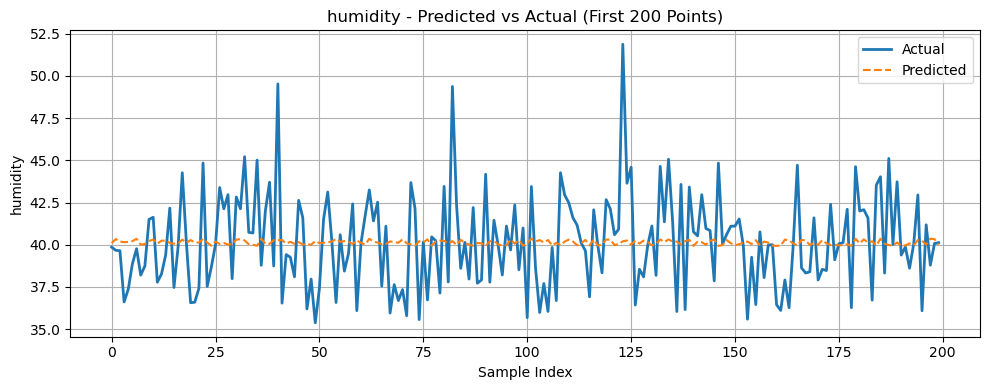

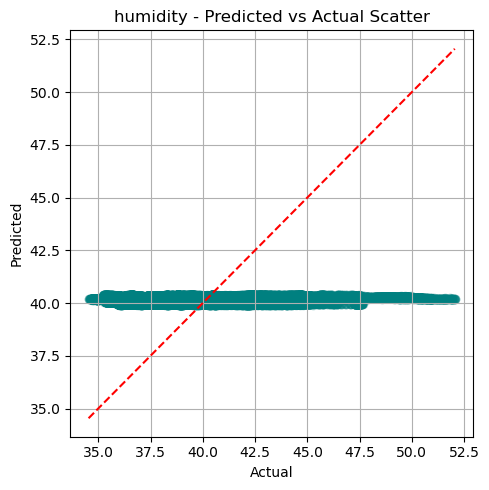

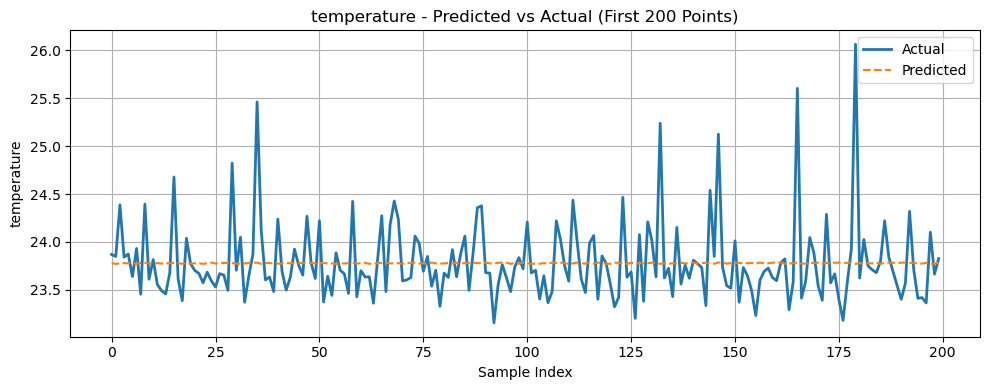

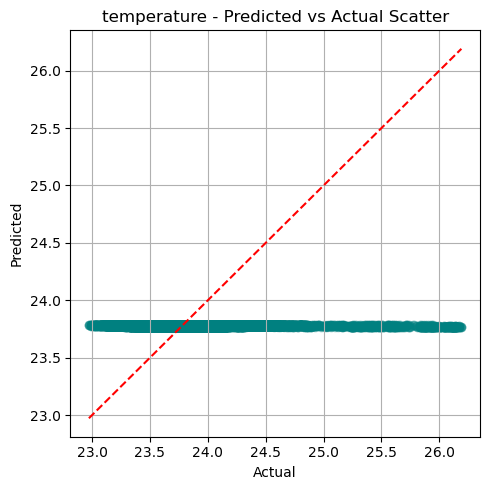

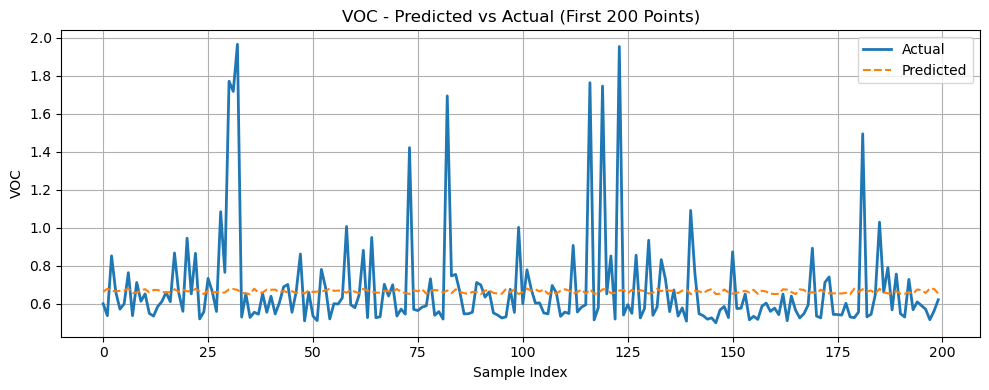

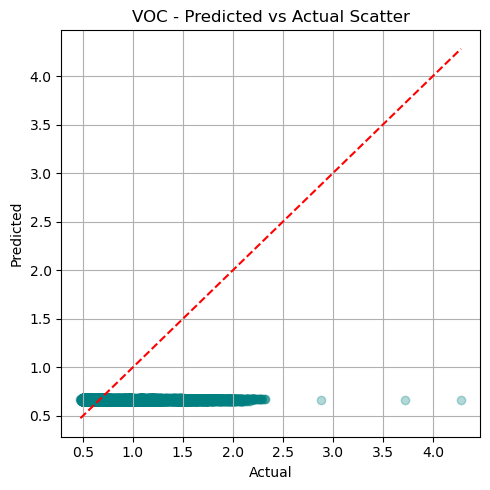

In [7]:
# Plot actual vs predicted for each target
for i, col in enumerate(y_all.columns):
    actual = y_test.iloc[:, i].values
    predicted = preds[:, i]

    # --- 1. Line Plot ---
    plt.figure(figsize=(10, 4))
    plt.plot(actual[:200], label='Actual', linewidth=2)
    plt.plot(predicted[:200], label='Predicted', linestyle='--')
    plt.title(f'{col} - Predicted vs Actual (First 200 Points)')
    plt.xlabel('Sample Index')
    plt.ylabel(col)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # --- 2. Scatter Plot ---
    plt.figure(figsize=(5, 5))
    plt.scatter(actual, predicted, alpha=0.3, color='teal')
    plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], 'r--')  # y=x line
    plt.title(f'{col} - Predicted vs Actual Scatter')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [10]:
df1 = df_voc.copy()
df2 = df_temperature.copy()
# Converting the 'time' column to datetime format for better handling of time series data.
df1["time"] = pd.to_datetime(df1["time"])
df2["time"] = pd.to_datetime(df2["time"])

Linear Regression model for VOC
RMSE: 0.22 
MAE: 0.137
Polynomial Regression for VOC
RMSE: 0.22 
MAE: 0.137
Lasso Regression for VOC
RMSE: 0.22 
MAE: 0.137


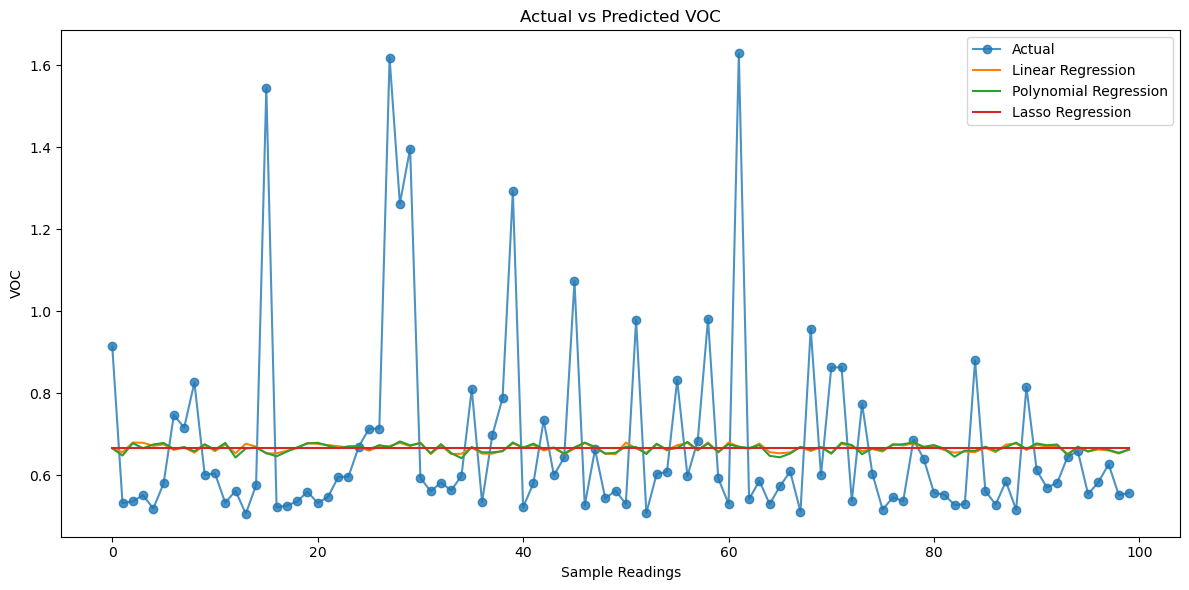

In [14]:
lr_model = LinearRegression()
lr_model.fit(X_train_v, y_train_v)
lr_pred = lr_model.predict(X_test_v)
lr_rmse = np.sqrt(mean_squared_error(y_test_v, lr_pred))
lr_mae = mean_absolute_error(y_test_v, lr_pred)
print("Linear Regression model for VOC")
print(f"RMSE: {round(lr_rmse,3)} \nMAE: {round(lr_mae,3)}")

poly_model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly_model.fit(X_train_v, y_train_v)
pm_pred = poly_model.predict(X_test_v)
pm_temp_rmse = np.sqrt(mean_squared_error(y_test_v, pm_pred))
pm_temp_mae = mean_absolute_error(y_test_v, pm_pred)
print(f"Polynomial Regression for VOC")
print(f"RMSE: {round(pm_temp_rmse,3)} \nMAE: {round(pm_temp_mae,3)}")

lasso = Lasso(alpha=0.1)
lasso.fit(X_train_v, y_train_v)
lasso_pred = lasso.predict(X_test_v)
lasso_rmse = np.sqrt(mean_squared_error(y_test_v, lasso_pred))
lasso_mae = mean_absolute_error(y_test_v, lasso_pred)   
print(f"Lasso Regression for VOC")
print(f"RMSE: {round(lasso_rmse,3)} \nMAE: {round(lasso_mae,3)}")

plt.figure(figsize=(12, 6))
plt.plot(y_test_v.values[:100], label="Actual", alpha=0.8, marker='o')
plt.plot(lr_pred[:100], label="Linear Regression")
plt.plot(pm_pred[:100], label="Polynomial Regression")
plt.plot(lasso_pred[:100], label="Lasso Regression")
plt.title("Actual vs Predicted VOC")
plt.xlabel("Sample Readings")
plt.ylabel("VOC")
plt.legend()
plt.tight_layout()
plt.show()

Linear Regression for Temperature
RMSE: 0.346 
MAE: 0.251
Polynomial Regression for Temperature
RMSE: 0.345 
MAE: 0.25
Lasso Regression for Temperature
RMSE: 0.346 
MAE: 0.251


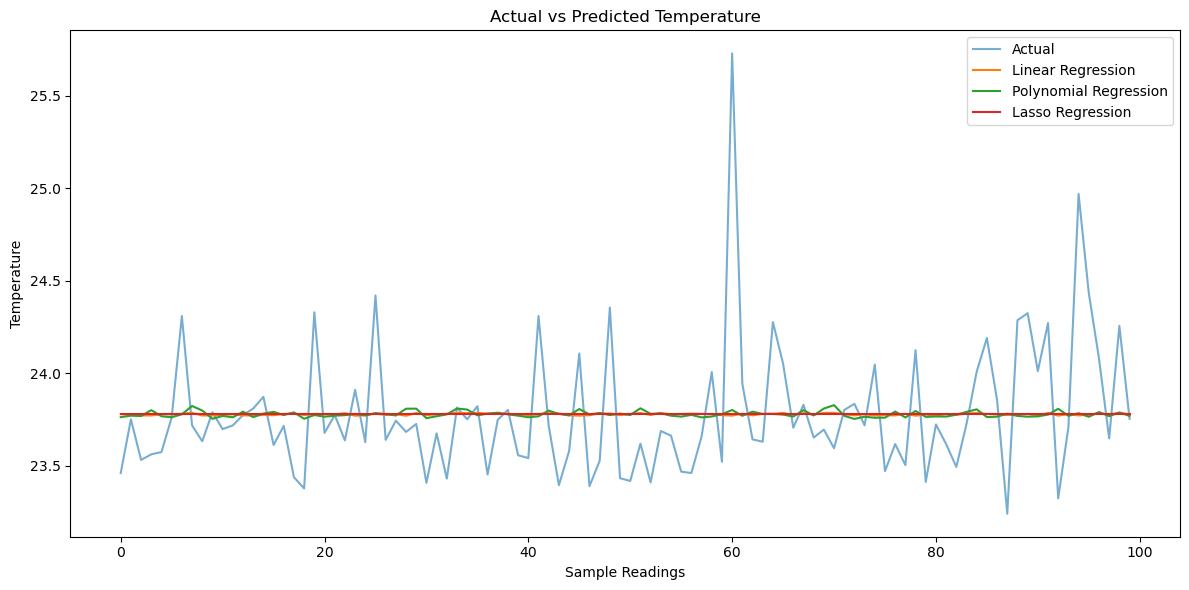

In [15]:
lr_temp = LinearRegression()
lr_temp.fit(X_train_t, y_train_t) 
lr_temp_pred = lr_temp.predict(X_test_t)
lr_temp_rmse = np.sqrt(mean_squared_error(y_test_t, lr_temp_pred))
lr_temp_mae = mean_absolute_error(y_test_t, lr_temp_pred)
print(f"Linear Regression for Temperature") 
print(f"RMSE: {round(lr_temp_rmse,3)} \nMAE: {round(lr_temp_mae,3)}")

poly_model_temp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly_model_temp.fit(X_train_t, y_train_t)
pm_pred_temp = poly_model_temp.predict(X_test_t)
pm_temp_rmse = np.sqrt(mean_squared_error(y_test_t, pm_pred_temp))
pm_temp_mae = mean_absolute_error(y_test_t, pm_pred_temp)
print(f"Polynomial Regression for Temperature")
print(f"RMSE: {round(pm_temp_rmse,3)} \nMAE: {round(pm_temp_mae,3)}")

lasso_temp = Lasso(alpha=0.1)
lasso_temp.fit(X_train_t, y_train_t)
lasso_pred_temp = lasso_temp.predict(X_test_t)
lasso_rmse_temp = np.sqrt(mean_squared_error(y_test_t, lasso_pred_temp))
lasso_mae_temp = mean_absolute_error(y_test_t, lasso_pred_temp)   
print(f"Lasso Regression for Temperature")
print(f"RMSE: {round(lasso_rmse_temp,3)} \nMAE: {round(lasso_mae_temp,3)}")

plt.figure(figsize=(12, 6))
plt.plot(y_test_t.values[:100], label="Actual", alpha=0.6)
plt.plot(lr_temp_pred[:100], label="Linear Regression")
plt.plot(pm_pred_temp[:100], label="Polynomial Regression")
plt.plot(lasso_pred_temp[:100], label="Lasso Regression")
plt.title("Actual vs Predicted Temperature")
plt.xlabel("Sample Readings")
plt.ylabel("Temperature")
plt.legend()
plt.tight_layout()
plt.show()